# 1.1 Análisis exploratorio de datos (EDA)

Analiza el **dataset original** descargado de Roboflow Universe (`Data_original`: 669 imágenes, 10 clases), sin ninguna corrección. Las correcciones se documentan en `1.2_limpieza_etiquetas.ipynb`.

| Sección | Contenido |
| :--- | :--- |
| 1 | Estructura e integridad |
| 2 | Distribución de clases |
| 3 | Imágenes: resolución y tamaño de archivo |
| 4 | Cajas: tamaño, forma y tamaño aparente del grano |
| 5 | Distribución espacial |
| 6 | Densidad y coocurrencia de clases |
| 7 | Muestras con anotaciones |
| 8 | Sesiones de captura y partición original |
| 9 | Calidad del etiquetado |
| 10 | Propuesta de consolidación de clases |
| 11 | Conclusiones |

Figuras en `salida/1.1_eda/`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd(); sys.path.insert(0, str(RAIZ))
SALIDA = RAIZ / 'salida' / '1.1_eda'

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from collections import Counter, defaultdict
from IPython.display import Image as Mostrar, display
import comun as C

C.estilo()
PALETA = C.paleta_clases()
DATA_ORIGINAL = C.ORIGINALES / 'Data_original'
inv = C.leer_dataset(DATA_ORIGINAL)
df = C.tabla_cajas(inv)
df['categoria'] = df.clase.map(C.CATEGORIA)
df['area'] = df.w * df.h
df['relacion_aspecto'] = df.w / df.h
print(f"{len(inv)} imágenes, {len(df)} cajas")

669 imágenes, 25376 cajas


## 1. Estructura e integridad

In [2]:
filas = []
for s in C.SPLITS:
    imgs = {p.stem for p in (DATA_ORIGINAL / s / 'images').glob('*')}
    lbls = {p.stem for p in (DATA_ORIGINAL / s / 'labels').glob('*.txt')}
    filas.append({'split': s, 'imágenes': len(imgs), 'etiquetas': len(lbls), 'imágenes sin etiqueta': len(imgs - lbls),
                  'etiquetas sin imagen': len(lbls - imgs), 'cajas': int((df.split == s).sum())})
estructura = pd.DataFrame(filas).set_index('split')
estructura.loc['total'] = estructura.sum()
estructura

,imágenes,etiquetas,imágenes sin etiqueta,etiquetas sin imagen,cajas
split,,,,,
train,459,459,0,0,17238
valid,146,146,0,0,5238
test,64,64,0,0,2900
total,669,669,0,0,25376


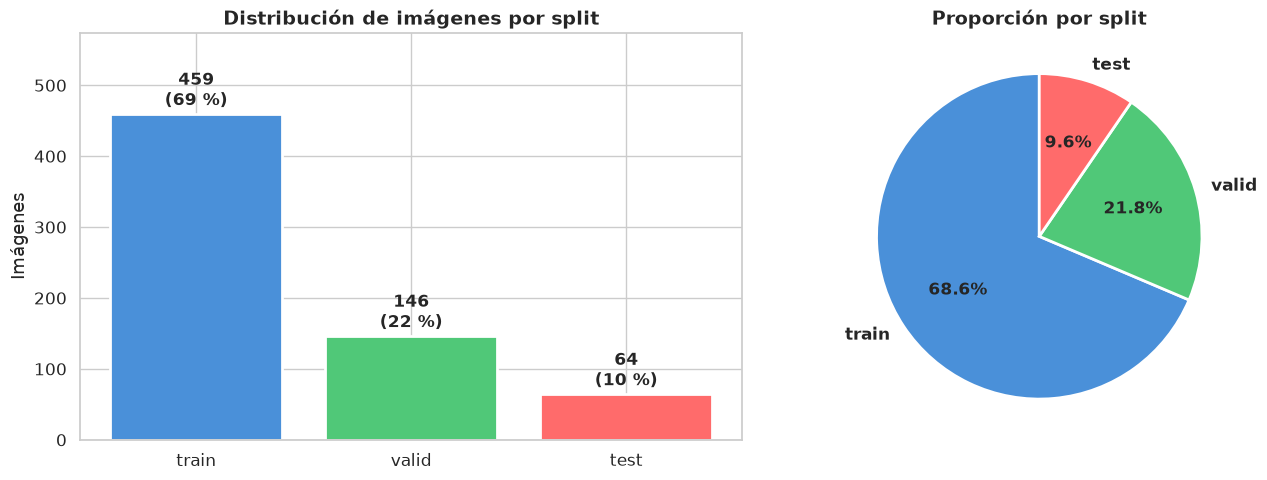

In [3]:
conteo = estructura.loc[list(C.SPLITS), 'imágenes']
colores = [C.COLOR_SPLIT[s] for s in C.SPLITS]
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
barras = ejes[0].bar(C.SPLITS, conteo, color=colores, edgecolor='white', linewidth=2)
for b, n in zip(barras, conteo):
    ejes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 5, f'{n}\n({100 * n / conteo.sum():.0f} %)',
                 ha='center', va='bottom', fontweight='bold', fontsize=12)
ejes[0].set_title('Distribución de imágenes por split'); ejes[0].set_ylabel('Imágenes'); ejes[0].set_ylim(0, conteo.max() * 1.25)
ejes[1].pie(conteo, labels=C.SPLITS, autopct='%1.1f%%', colors=colores, startangle=90,
            textprops={'fontsize': 12, 'fontweight': 'bold'}, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ejes[1].set_title('Proporción por split')
C.guardar(SALIDA, 'eda_distribucion_splits.png')

## 2. Distribución de clases

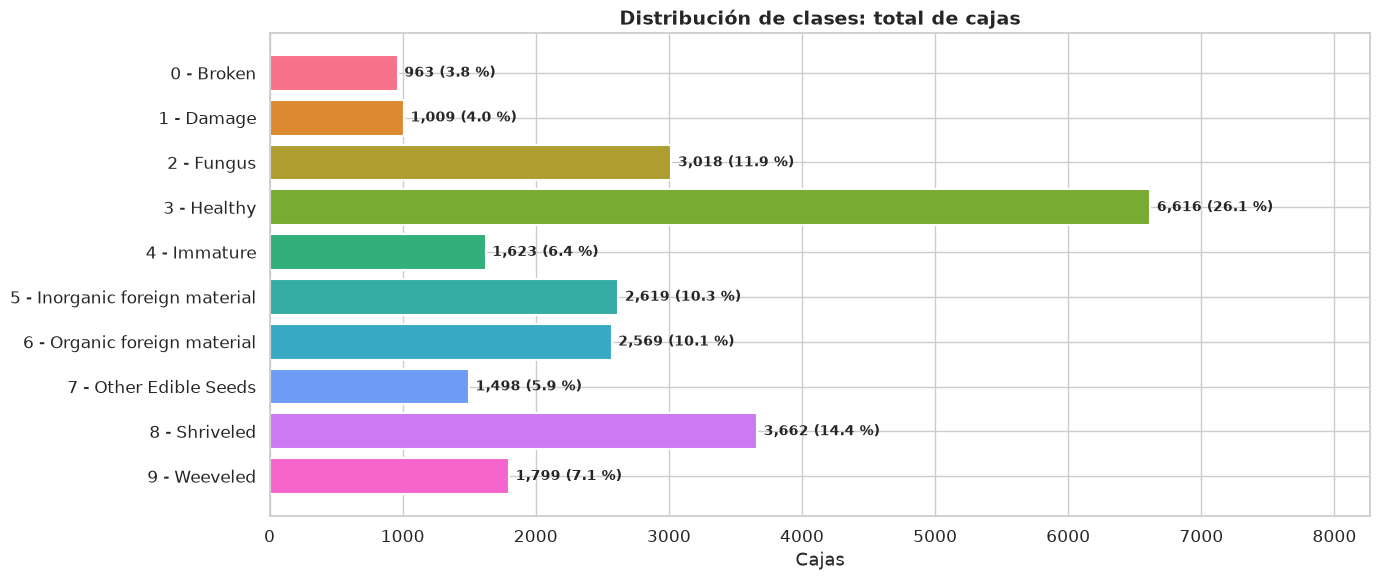

,cajas,%
clase,,
Broken,963,3.79
Damage,1009,3.98
Fungus,3018,11.89
Healthy,6616,26.07
Immature,1623,6.40
Inorganic foreign material,2619,10.32
Organic foreign material,2569,10.12
Other Edible Seeds,1498,5.90
Shriveled,3662,14.43


In [4]:
conteo_clases = df.clase.value_counts().reindex(C.CLASES).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(14, 6))
ax.barh(range(len(C.CLASES)), conteo_clases.values, color=[PALETA[c] for c in C.CLASES], edgecolor='white', linewidth=1.5)
for i, n in enumerate(conteo_clases.values):
    ax.text(n + 50, i, f'{n:,} ({100 * n / len(df):.1f} %)', va='center', fontsize=10, fontweight='bold')
ax.set_yticks(range(len(C.CLASES))); ax.set_yticklabels([f'{i} - {n}' for i, n in enumerate(C.CLASES)])
ax.set_xlabel('Cajas'); ax.set_title('Distribución de clases: total de cajas'); ax.set_xlim(0, conteo_clases.max() * 1.25)
ax.invert_yaxis()
C.guardar(SALIDA, 'eda_distribucion_clases.png')
pd.DataFrame({'cajas': conteo_clases, '%': (100 * conteo_clases / len(df)).round(2)})

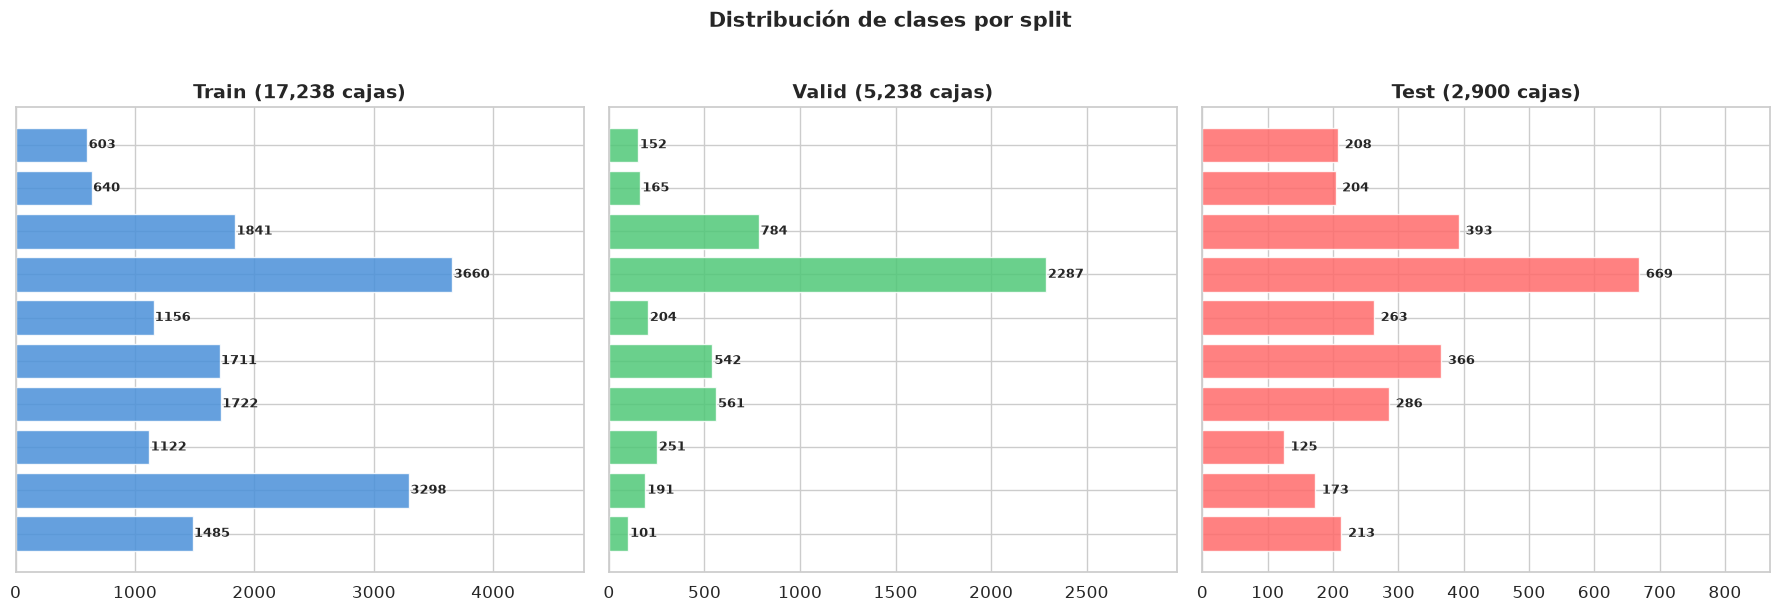

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, s in zip(ejes, C.SPLITS):
    n = df[df.split == s].clase.value_counts().reindex(C.CLASES, fill_value=0)
    ax.barh(range(len(C.CLASES)), n.values, color=C.COLOR_SPLIT[s], edgecolor='white', alpha=0.85)
    for i, v in enumerate(n.values):
        ax.text(v + 10, i, str(v), va='center', fontsize=9, fontweight='bold')
    ax.set_yticks(range(len(C.CLASES))); ax.set_yticklabels(C.CLASES if s == 'train' else [])
    ax.set_title(f'{s.capitalize()} ({n.sum():,} cajas)'); ax.set_xlim(0, n.max() * 1.3); ax.invert_yaxis()
fig.suptitle('Distribución de clases por split', fontsize=15, fontweight='bold', y=1.02)
C.guardar(SALIDA, 'eda_distribucion_clases_splits.png')

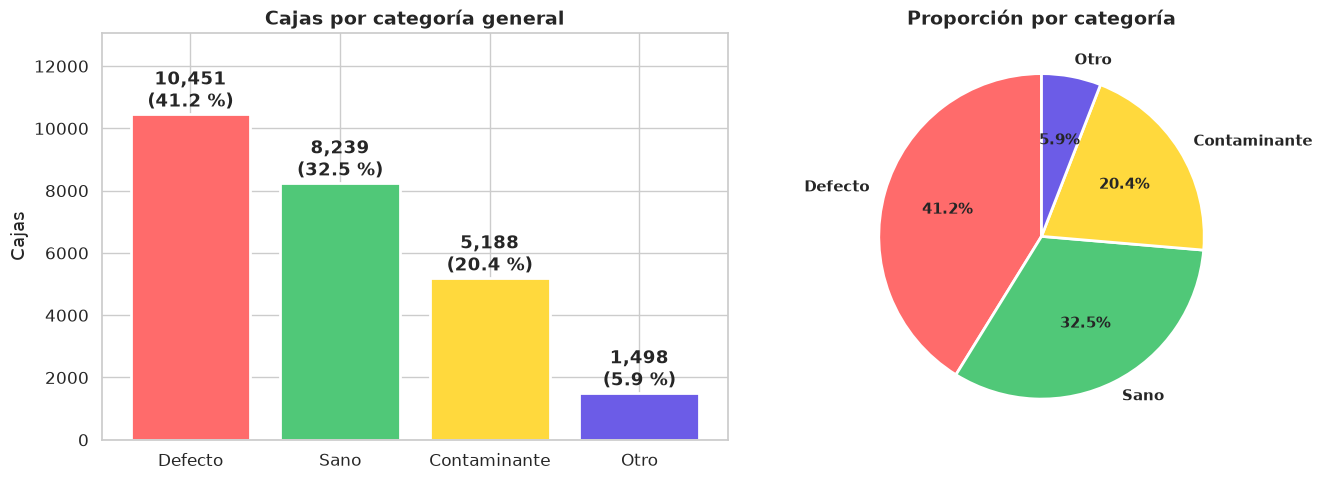

In [6]:
cat = df.categoria.value_counts()
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
barras = ejes[0].bar(cat.index, cat.values, color=[C.COLOR_CATEGORIA[c] for c in cat.index], edgecolor='white', linewidth=2)
for b, v in zip(barras, cat.values):
    ejes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 50, f'{v:,}\n({100 * v / len(df):.1f} %)',
                 ha='center', va='bottom', fontweight='bold')
ejes[0].set_title('Cajas por categoría general'); ejes[0].set_ylabel('Cajas'); ejes[0].set_ylim(0, cat.max() * 1.25)
ejes[1].pie(cat.values, labels=cat.index, autopct='%1.1f%%', colors=[C.COLOR_CATEGORIA[c] for c in cat.index],
            startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'}, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ejes[1].set_title('Proporción por categoría')
C.guardar(SALIDA, 'eda_distribucion_categorias.png')

## 3. Imágenes: resolución y tamaño de archivo

9 resoluciones distintas; media 13.8 MP; verticales 92.8 %


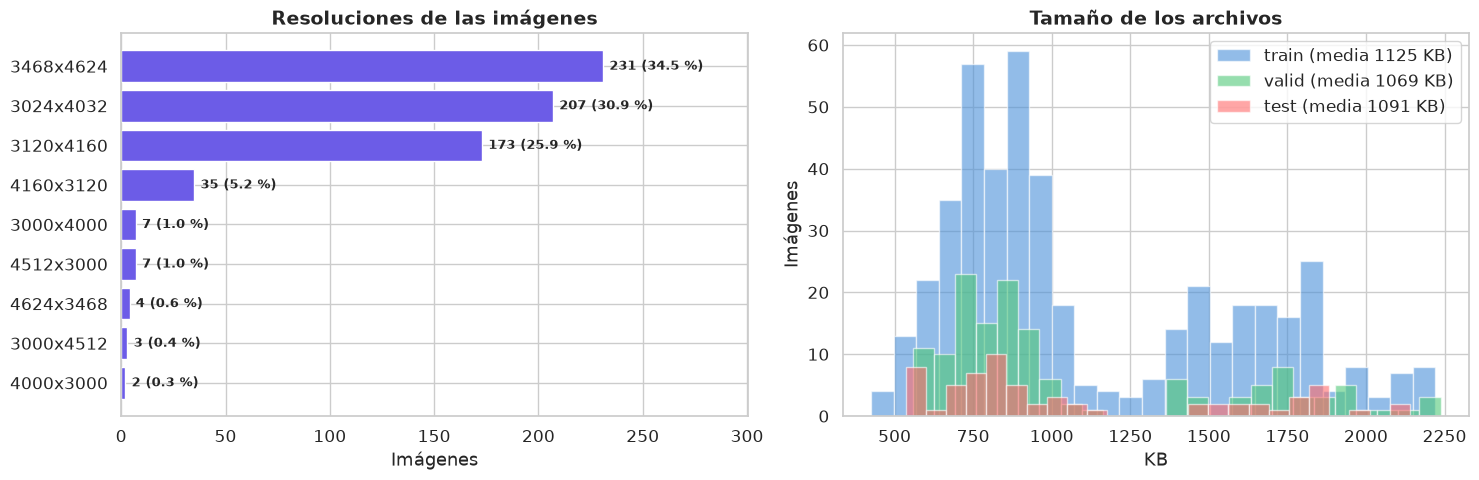

,,imágenes,%
ancho,alto,,
3468,4624,231,34.5
3024,4032,207,30.9
3120,4160,173,25.9
4160,3120,35,5.2
3000,4000,7,1.0
4512,3000,7,1.0
4624,3468,4,0.6
3000,4512,3,0.4
4000,3000,2,0.3


In [7]:
imgs = pd.DataFrame([{'split': r['split'], 'ancho': r['W'], 'alto': r['H'], 'MP': r['W'] * r['H'] / 1e6,
                      'kb': r['img'].stat().st_size / 1024} for r in inv])
res = imgs.groupby(['ancho', 'alto']).size().sort_values(ascending=False).rename('imágenes').to_frame()
res['%'] = (100 * res['imágenes'] / len(imgs)).round(1)
print(f"{len(res)} resoluciones distintas; media {imgs.MP.mean():.1f} MP; verticales {100 * (imgs.alto > imgs.ancho).mean():.1f} %")
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
etiquetas = [f'{a}x{h}' for a, h in res.index]
ejes[0].barh(etiquetas, res['imágenes'], color='#6C5CE7', edgecolor='white'); ejes[0].invert_yaxis()
for i, (n, p) in enumerate(zip(res['imágenes'], res['%'])):
    ejes[0].text(n + 3, i, f'{n} ({p} %)', va='center', fontsize=9, fontweight='bold')
ejes[0].set_title('Resoluciones de las imágenes'); ejes[0].set_xlabel('Imágenes'); ejes[0].set_xlim(0, res['imágenes'].max() * 1.3)
for s in C.SPLITS:
    d = imgs[imgs.split == s].kb
    ejes[1].hist(d, bins=25, alpha=0.6, color=C.COLOR_SPLIT[s], edgecolor='white', label=f'{s} (media {d.mean():.0f} KB)')
ejes[1].set_title('Tamaño de los archivos'); ejes[1].set_xlabel('KB'); ejes[1].set_ylabel('Imágenes'); ejes[1].legend()
C.guardar(SALIDA, 'eda_distribucion_tamanios.png')
res

## 4. Cajas: tamaño, forma y tamaño aparente del grano

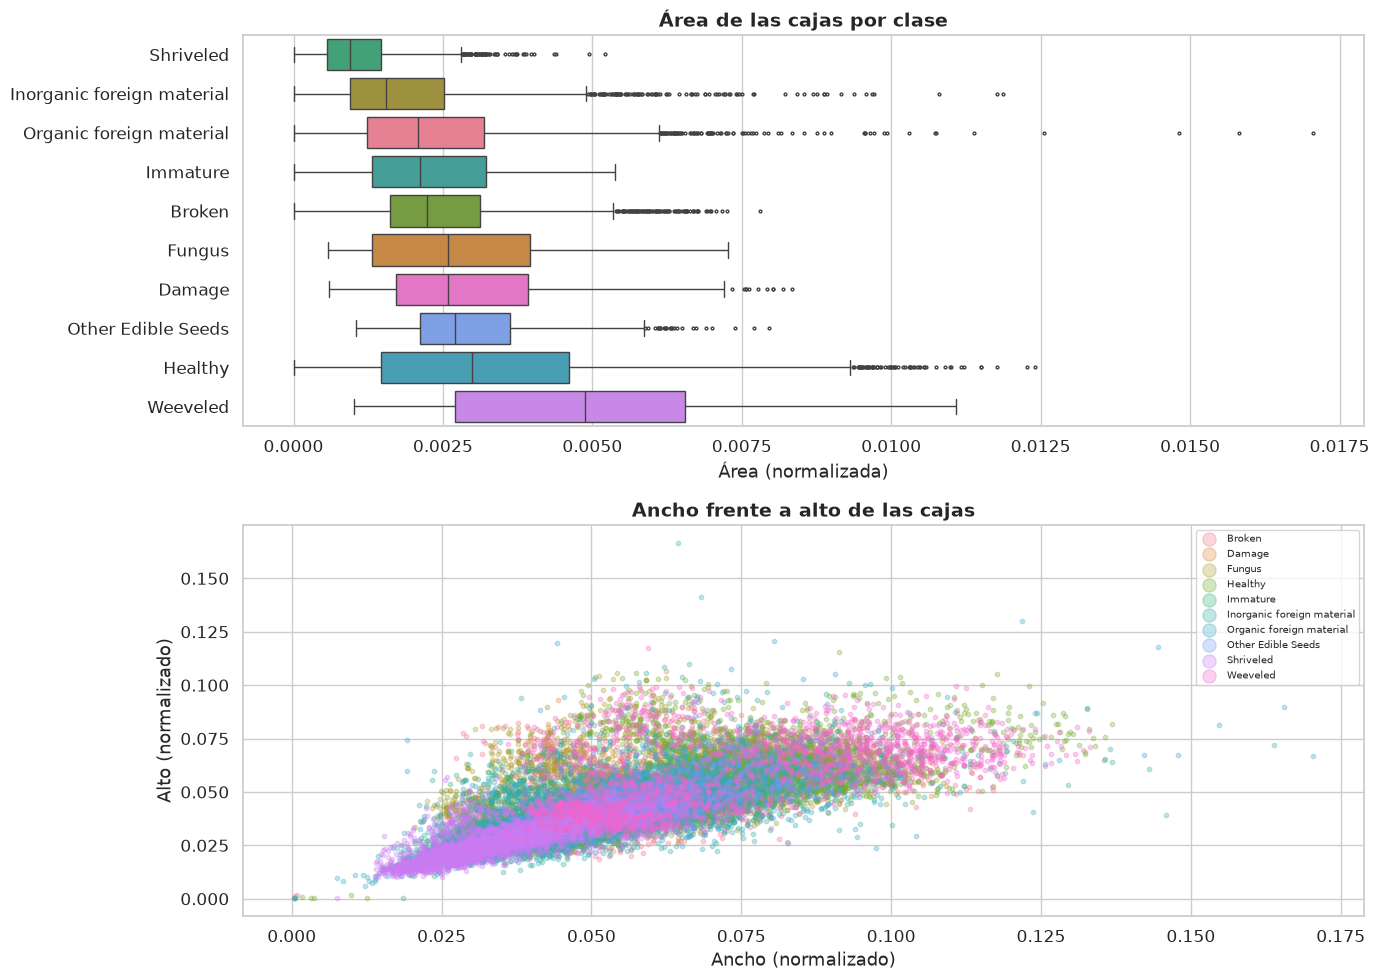

In [8]:
orden = df.groupby('clase').area.median().sort_values().index
fig, ejes = plt.subplots(2, 1, figsize=(14, 10))
sns.boxplot(data=df, x='area', y='clase', order=orden, ax=ejes[0], palette=[PALETA[c] for c in orden], fliersize=2, hue='clase', legend=False)
ejes[0].set_title('Área de las cajas por clase'); ejes[0].set_xlabel('Área (normalizada)'); ejes[0].set_ylabel('')
for c in C.CLASES:
    d = df[df.clase == c]
    ejes[1].scatter(d.w, d.h, alpha=0.3, s=10, color=PALETA[c], label=c)
ejes[1].set_title('Ancho frente a alto de las cajas'); ejes[1].set_xlabel('Ancho (normalizado)'); ejes[1].set_ylabel('Alto (normalizado)')
ejes[1].legend(fontsize=7, markerscale=3, loc='upper right')
C.guardar(SALIDA, 'eda_tamano_bboxes.png')

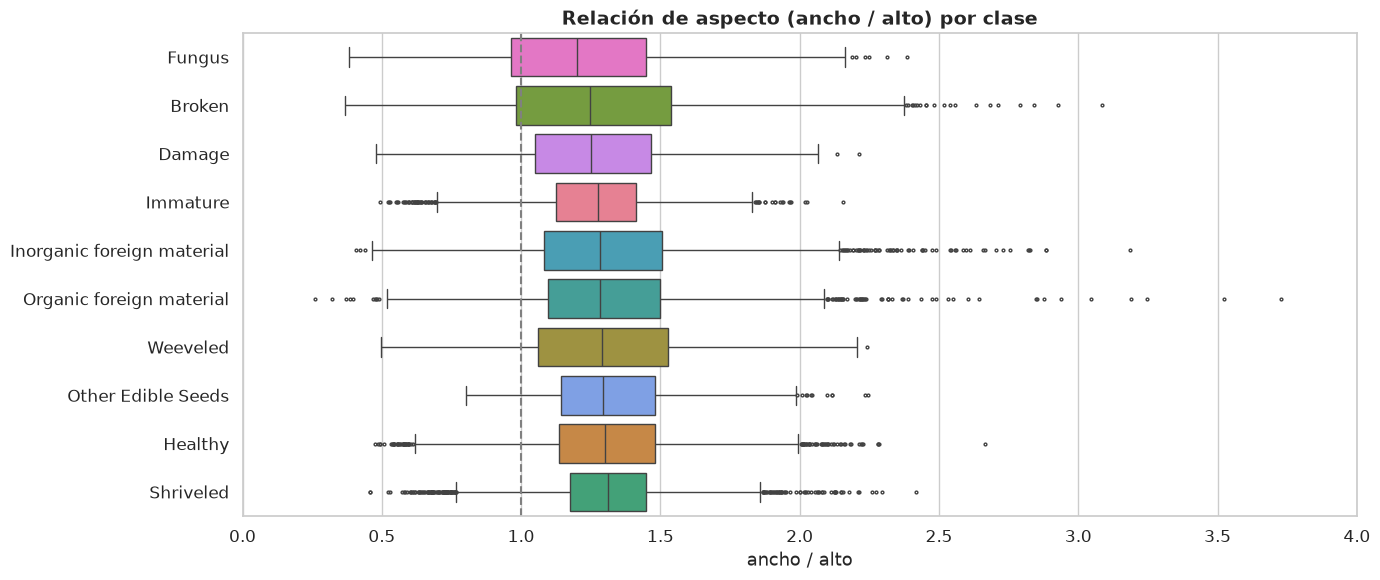

Cajas con relación de aspecto > 10: 5 (trazos de casi 1 px de alto)


In [9]:
orden_ar = df.groupby('clase').relacion_aspecto.median().sort_values().index
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=df, x='relacion_aspecto', y='clase', order=orden_ar, ax=ax, palette=[PALETA[c] for c in orden_ar],
            fliersize=2, hue='clase', legend=False)
ax.axvline(1, color='grey', ls='--'); ax.set_xlim(0, 4)
ax.set_title('Relación de aspecto (ancho / alto) por clase'); ax.set_xlabel('ancho / alto'); ax.set_ylabel('')
C.guardar(SALIDA, 'eda_aspect_ratio_bboxes.png')
print(f"Cajas con relación de aspecto > 10: {(df.relacion_aspecto > 10).sum()} (trazos de casi 1 px de alto)")

Tamaño aparente del grano (lado menor de la caja) según la resolución de entrada de la red. Solo clases de maíz.

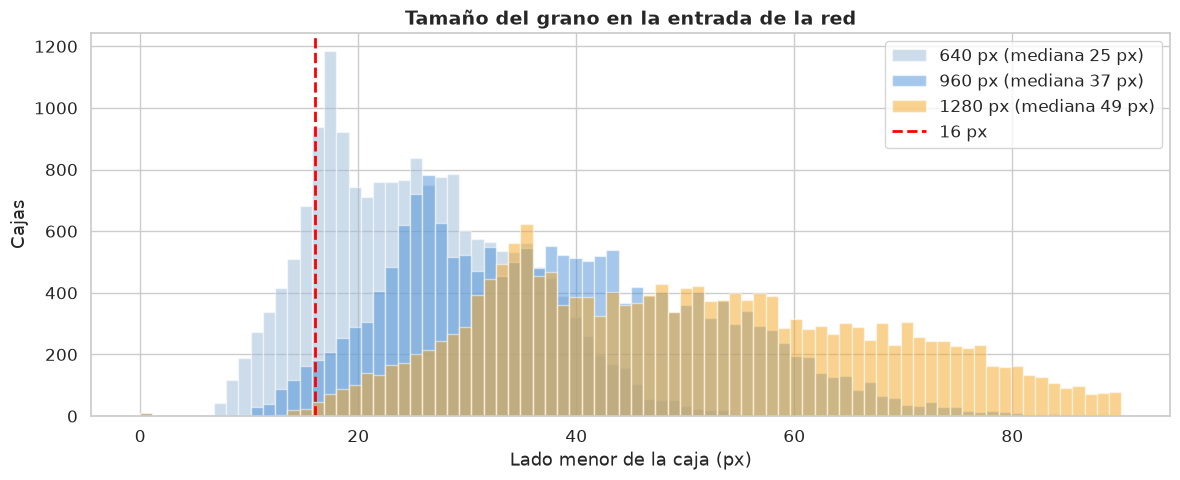

,resolución,mediana (px),percentil 5 (px),% < 16 px,% < 24 px
0,640,24.6,12.3,14.6,47.5
1,960,37.0,18.5,2.7,14.6
2,1280,49.3,24.6,0.4,4.5


In [10]:
maiz = df[df.id_clase.isin(C.CLASES_MAIZ)]
filas = []
fig, ax = plt.subplots(figsize=(12, 5))
for r_in, color in ((640, '#9BBBD9'), (960, '#4A90D9'), (1280, '#F5A623')):
    lado = maiz.lado_menor_960 * r_in / 960
    filas.append({'resolución': r_in, 'mediana (px)': round(lado.median(), 1), 'percentil 5 (px)': round(lado.quantile(0.05), 1),
                  '% < 16 px': round(100 * (lado < 16).mean(), 1), '% < 24 px': round(100 * (lado < 24).mean(), 1)})
    ax.hist(lado, bins=80, range=(0, 90), alpha=0.5, color=color, edgecolor='white', label=f'{r_in} px (mediana {lado.median():.0f} px)')
ax.axvline(16, color='red', ls='--', lw=2, label='16 px')
ax.set_title('Tamaño del grano en la entrada de la red'); ax.set_xlabel('Lado menor de la caja (px)'); ax.set_ylabel('Cajas'); ax.legend()
C.guardar(SALIDA, 'eda_tamano_grano_resolucion.png')
pd.DataFrame(filas)

## 5. Distribución espacial

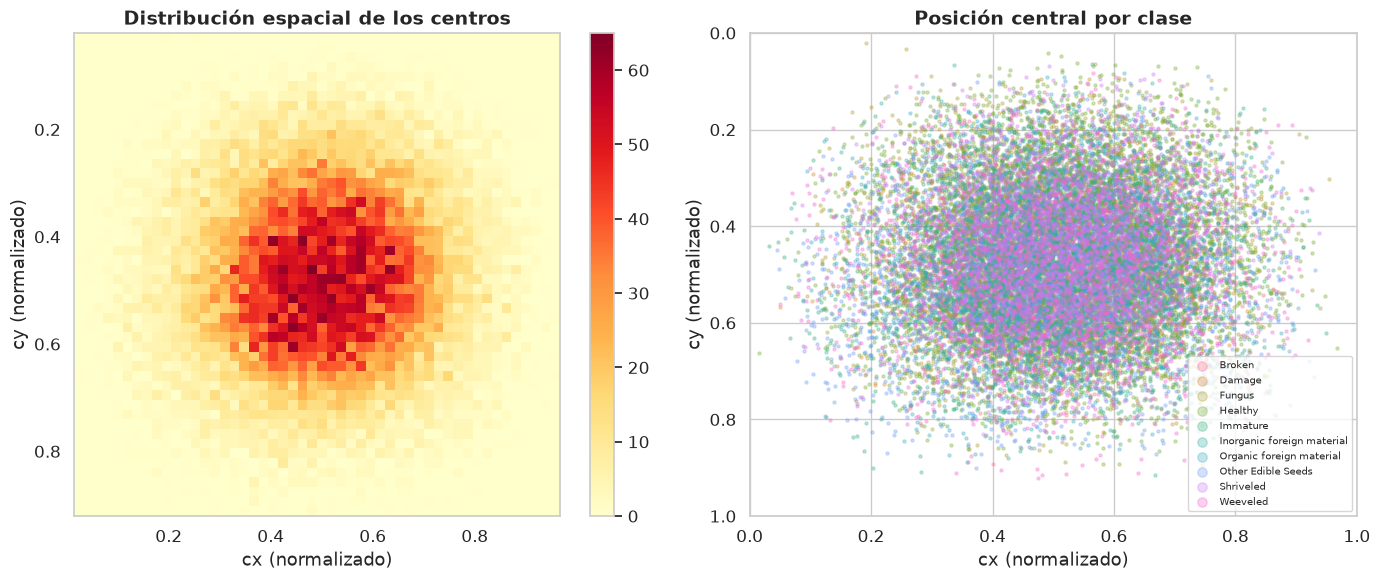

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
h = ejes[0].hist2d(df.cx, df.cy, bins=50, cmap='YlOrRd')
ejes[0].set_title('Distribución espacial de los centros'); ejes[0].set_xlabel('cx (normalizado)'); ejes[0].set_ylabel('cy (normalizado)')
ejes[0].invert_yaxis(); plt.colorbar(h[3], ax=ejes[0])
for c in C.CLASES:
    d = df[df.clase == c]
    ejes[1].scatter(d.cx, d.cy, alpha=0.3, s=5, color=PALETA[c], label=c)
ejes[1].set_title('Posición central por clase'); ejes[1].set_xlabel('cx (normalizado)'); ejes[1].set_ylabel('cy (normalizado)')
ejes[1].set_xlim(0, 1); ejes[1].set_ylim(0, 1); ejes[1].invert_yaxis(); ejes[1].legend(fontsize=7, markerscale=3)
C.guardar(SALIDA, 'eda_distribucion_espacial.png')

## 6. Densidad y coocurrencia de clases

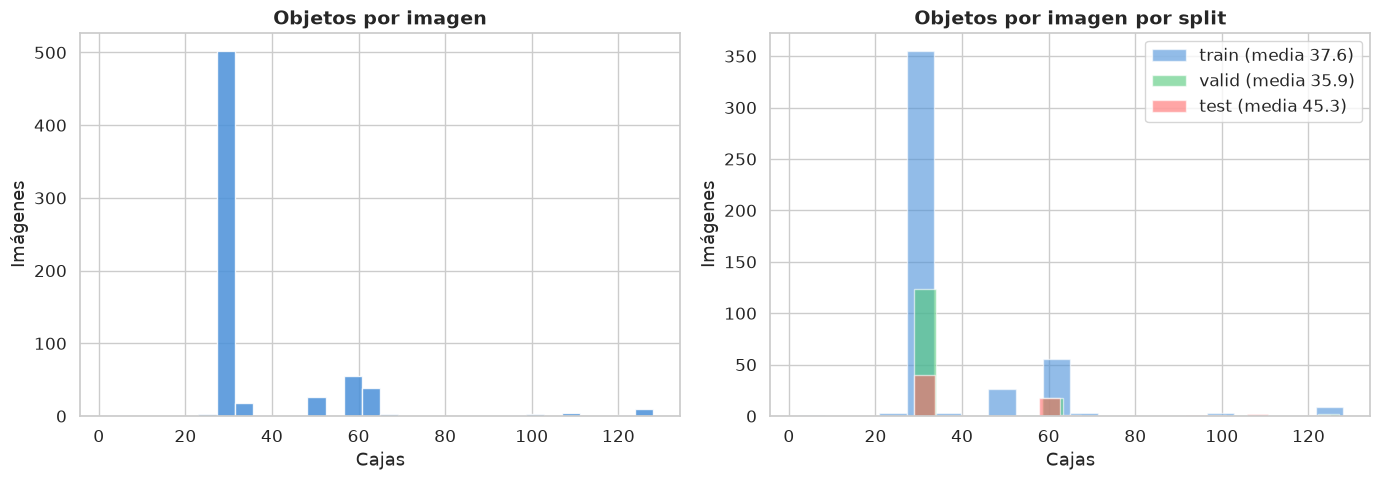

Media 37.9; mediana 30; mínimo 2; máximo 128


In [12]:
por_img = pd.DataFrame([{'base': r['base'], 'split': r['split'], 'cajas': len(r['clases']),
                         'clases': frozenset(C.CLASES[c] for c in r['clases'])} for r in inv])
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
ejes[0].hist(por_img.cajas, bins=30, color='#4A90D9', edgecolor='white', alpha=0.85)
ejes[0].set_title('Objetos por imagen'); ejes[0].set_xlabel('Cajas'); ejes[0].set_ylabel('Imágenes')
for s in C.SPLITS:
    d = por_img[por_img.split == s].cajas
    ejes[1].hist(d, bins=20, alpha=0.6, color=C.COLOR_SPLIT[s], edgecolor='white', label=f'{s} (media {d.mean():.1f})')
ejes[1].set_title('Objetos por imagen por split'); ejes[1].set_xlabel('Cajas'); ejes[1].set_ylabel('Imágenes'); ejes[1].legend()
C.guardar(SALIDA, 'eda_objetos_por_imagen.png')
print(f"Media {por_img.cajas.mean():.1f}; mediana {por_img.cajas.median():.0f}; mínimo {por_img.cajas.min()}; máximo {por_img.cajas.max()}")

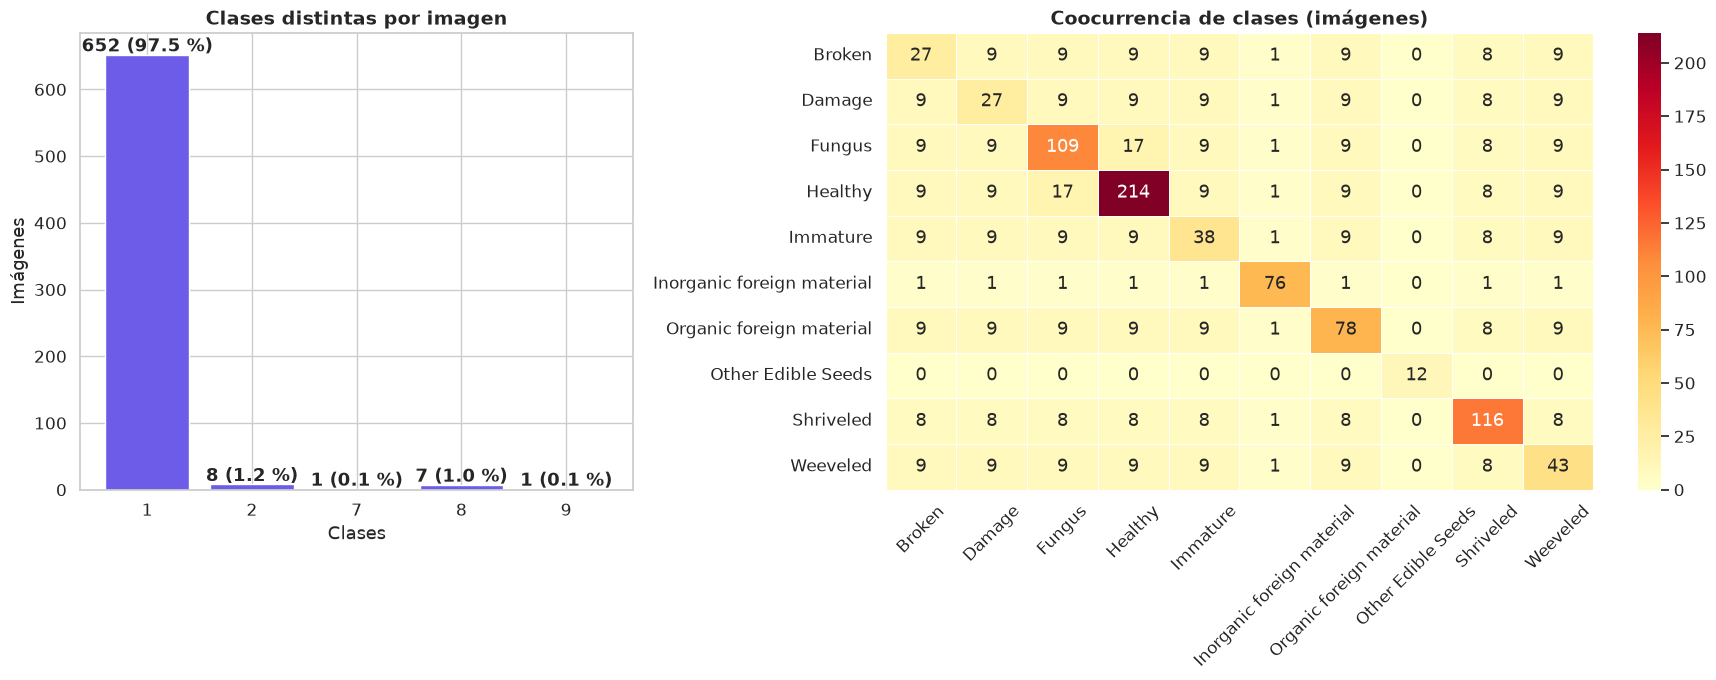

Imágenes con una sola clase: 97.5 %


In [13]:
por_img['n_clases'] = por_img.clases.apply(len)
cooc = np.zeros((len(C.CLASES), len(C.CLASES)), dtype=int)
for cl in por_img.clases:
    for a in cl:
        for b in cl:
            cooc[C.CLASES.index(a), C.CLASES.index(b)] += 1
fig, ejes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1, 1.6]})
vc = por_img.n_clases.value_counts().sort_index()
ejes[0].bar(vc.index.astype(str), vc.values, color='#6C5CE7', edgecolor='white')
for x, v in zip(vc.index.astype(str), vc.values):
    ejes[0].text(x, v + 5, f'{v} ({100 * v / len(por_img):.1f} %)', ha='center', fontweight='bold')
ejes[0].set_title('Clases distintas por imagen'); ejes[0].set_xlabel('Clases'); ejes[0].set_ylabel('Imágenes')
sns.heatmap(cooc, xticklabels=C.CLASES, yticklabels=C.CLASES, annot=True, fmt='d', cmap='YlOrRd', ax=ejes[1], linewidths=0.5)
ejes[1].set_title('Coocurrencia de clases (imágenes)'); ejes[1].tick_params(axis='x', rotation=45)
C.guardar(SALIDA, 'eda_coocurrencia_clases.png')
print(f"Imágenes con una sola clase: {100 * (por_img.n_clases == 1).mean():.1f} %")

## 7. Muestras con anotaciones

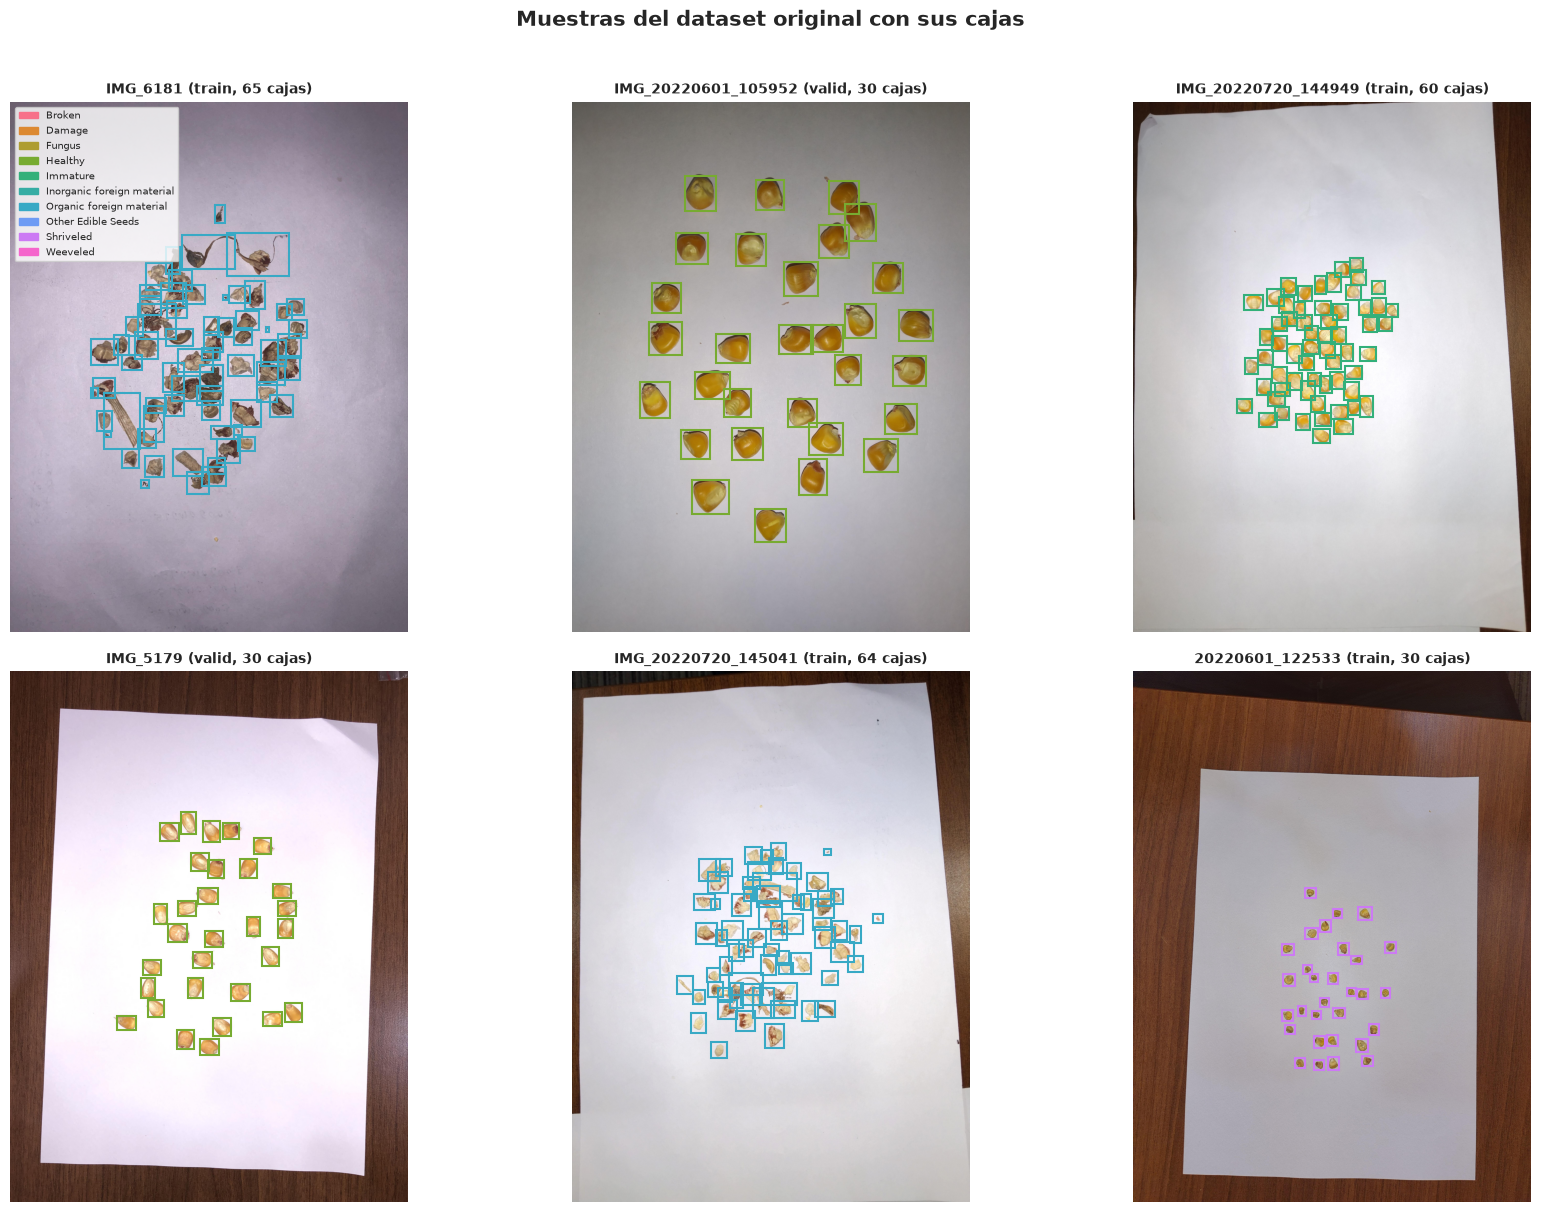

In [14]:
rng = np.random.default_rng(42)
muestras = [inv[i] for i in rng.choice(len(inv), 6, replace=False)]
fig, ejes = plt.subplots(2, 3, figsize=(18, 12))
for ax, r in zip(ejes.flat, muestras):
    ax.imshow(cv2.cvtColor(cv2.imread(str(r['img'])), cv2.COLOR_BGR2RGB))
    for (x1, y1, x2, y2), c in zip(r['xyxy'], r['clases']):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor=PALETA[C.CLASES[c]], facecolor='none'))
    ax.set_title(f"{C.nombre_roboflow(r['stem'])} ({r['split']}, {len(r['clases'])} cajas)", fontsize=10); ax.axis('off')
ejes.flat[0].legend(handles=[patches.Patch(color=PALETA[c], label=c) for c in C.CLASES], fontsize=7, loc='upper left')
fig.suptitle('Muestras del dataset original con sus cajas', fontsize=15, fontweight='bold', y=1.01)
C.guardar(SALIDA, 'eda_muestras.png')

## 8. Sesiones de captura y partición original

Los nombres de archivo codifican la hora de captura (`AAAAMMDD_HHMMSS`) o el contador de la cámara (`IMG_NNNN`, `DSC_NNNN`). Las fotos separadas por 60 s o menos (o 2 posiciones de contador) forman una **sesión**: la misma bandeja fotografiada en ráfaga.

64 sesiones; tamaño máximo 78, mediana 5
Peso mediano de la clase dominante dentro de su sesión: 100.0 %
Sesiones repartidas entre varios splits: 36 (584 imágenes)


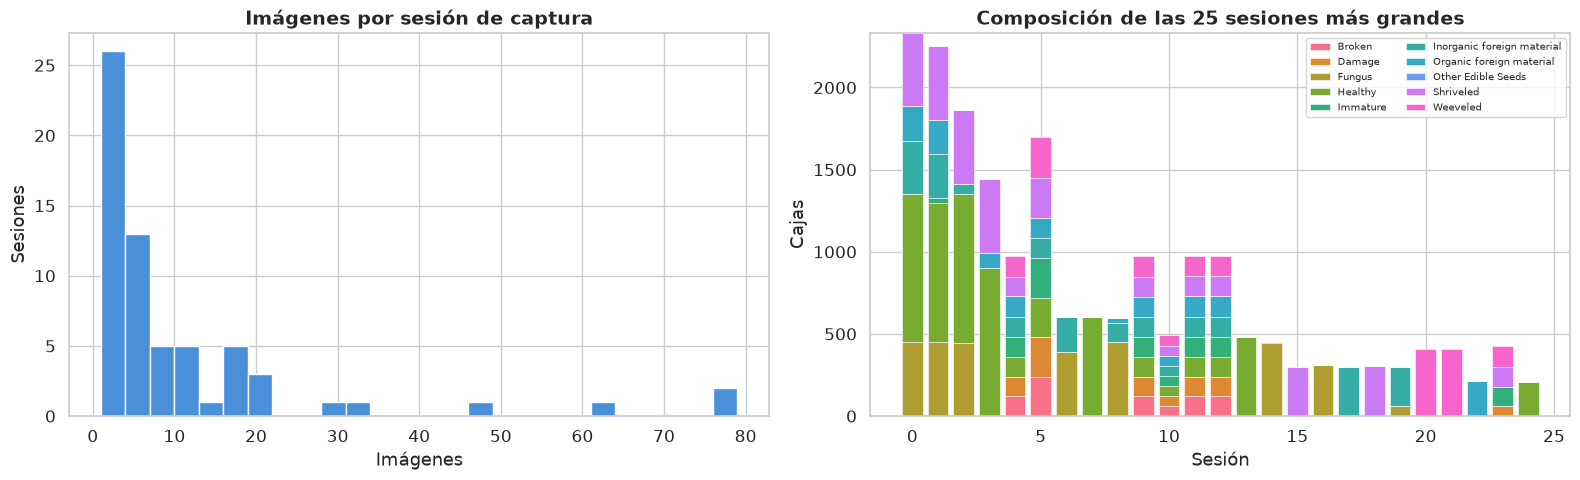

,sesiones
test/train/valid,21
train/valid,10
test/train,4
test/valid,1


In [15]:
ses = defaultdict(list)
for r in inv:
    ses[r['sesion']].append(r)
tam = pd.Series({s: len(v) for s, v in ses.items()})
comp = {s: Counter(C.CLASES[c] for r in rs for c in r['clases']) for s, rs in ses.items()}
dominio = pd.Series({s: max(c.values()) / sum(c.values()) for s, c in comp.items() if c})
cruzan = {s: '/'.join(sorted({r['split'] for r in rs})) for s, rs in ses.items() if len({r['split'] for r in rs}) > 1}
print(f'{len(ses)} sesiones; tamaño máximo {tam.max()}, mediana {int(tam.median())}')
print(f'Peso mediano de la clase dominante dentro de su sesión: {100 * dominio.median():.1f} %')
print(f'Sesiones repartidas entre varios splits: {len(cruzan)} ({sum(len(ses[s]) for s in cruzan)} imágenes)')
fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
ejes[0].hist(tam, bins=range(1, tam.max() + 4, 3), color='#4A90D9', edgecolor='white')
ejes[0].set_title('Imágenes por sesión de captura'); ejes[0].set_xlabel('Imágenes'); ejes[0].set_ylabel('Sesiones')
mayores = tam.sort_values(ascending=False).index[:25]
abajo = np.zeros(len(mayores))
for c in C.CLASES:
    v = np.array([comp[s].get(c, 0) for s in mayores], float)
    ejes[1].bar(range(len(mayores)), v, bottom=abajo, color=PALETA[c], label=c, edgecolor='white', linewidth=0.4); abajo += v
ejes[1].set_title('Composición de las 25 sesiones más grandes'); ejes[1].set_xlabel('Sesión'); ejes[1].set_ylabel('Cajas')
ejes[1].legend(fontsize=7, ncol=2)
C.guardar(SALIDA, 'eda_sesiones.png')
pd.Series(cruzan).value_counts().rename('sesiones').to_frame()

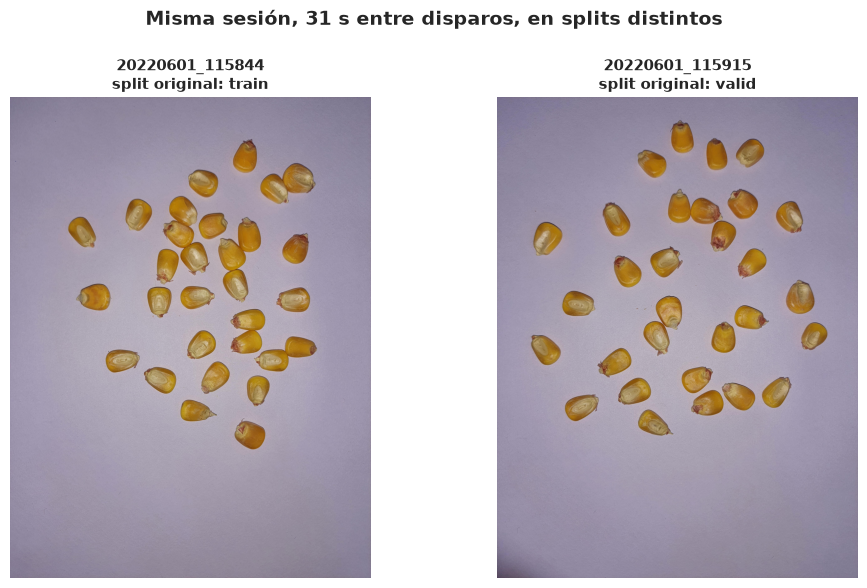

In [16]:
ejemplo = None
for s in cruzan:
    rs = sorted(ses[s], key=lambda r: C.clave_captura(r['stem'])[1])
    for a, b in zip(rs, rs[1:]):
        if a['split'] != b['split'] and C.clave_captura(a['stem'])[0] == 'tiempo':
            ejemplo = (a, b); break
    if ejemplo: break
fig, ejes = plt.subplots(1, 2, figsize=(10, 6))
for ax, r in zip(ejes, ejemplo):
    ax.imshow(cv2.cvtColor(cv2.imread(str(r['img'])), cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f"{C.nombre_roboflow(r['stem'])}\nsplit original: {r['split']}", fontsize=11)
dt = abs(C.clave_captura(ejemplo[0]['stem'])[1] - C.clave_captura(ejemplo[1]['stem'])[1])
fig.suptitle(f'Misma sesión, {dt:.0f} s entre disparos, en splits distintos', fontsize=14, fontweight='bold')
C.guardar(SALIDA, 'eda_sesion_entre_splits.png')

## 9. Calidad del etiquetado

Controles automáticos sobre las cajas (`comun.py`). Cada caja se informa una sola vez: una caja degenerada no se repite como "tamaño atípico".

| Problema | Criterio |
| :--- | :--- |
| Caja degenerada | Lado menor de menos de 3 px a 960 |
| Relación de aspecto atípica | Caja de maíz con ancho/alto > 4 o < 0.25 |
| Cajas duplicadas | Dos cajas con IoU > 0.85 |
| Tamaño atípico | Área anormal para su clase (z robusto > 3.5) |
| Clase rara en sesión casi monoclase | Clase con menos del 3 % de las cajas en una sesión dominada (≥ 85 %) por otra |
| Posible etiquetado incompleto | Imagen con muchas menos cajas que la mediana de su sesión |

In [17]:
problemas = C.detectar(inv)
print(f'{len(problemas)} problemas en {problemas.stem.nunique()} imágenes')
problemas.groupby(['tipo', 'split']).size().unstack(fill_value=0)

56 problemas en 39 imágenes


split,test,train,valid
tipo,,,
Caja degenerada,4,8,1
Cajas duplicadas,0,11,5
Clase rara en sesión casi monoclase,6,6,1
Posible etiquetado incompleto,0,1,0
Tamaño atípico,1,10,2


Un ejemplo de cada tipo (izquierda: imagen completa con el problema rodeado; derecha: recorte ampliado; caja señalada en rojo, su duplicada en azul).

Caja degenerada - lado menor 0.6 px a 960


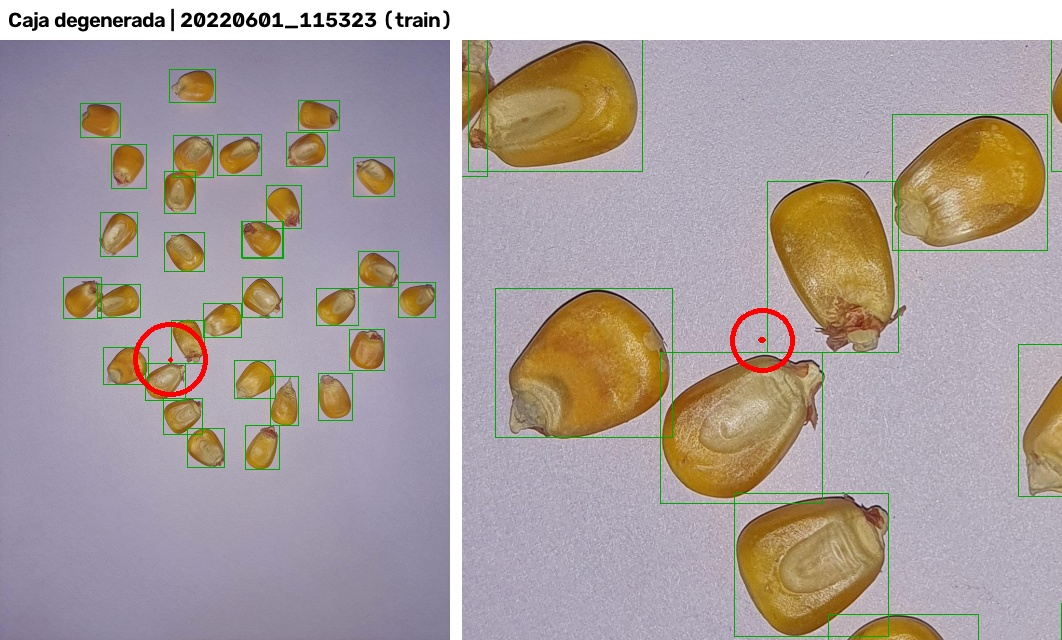

Cajas duplicadas - IoU 0.86 con otra caja (Weeveled)


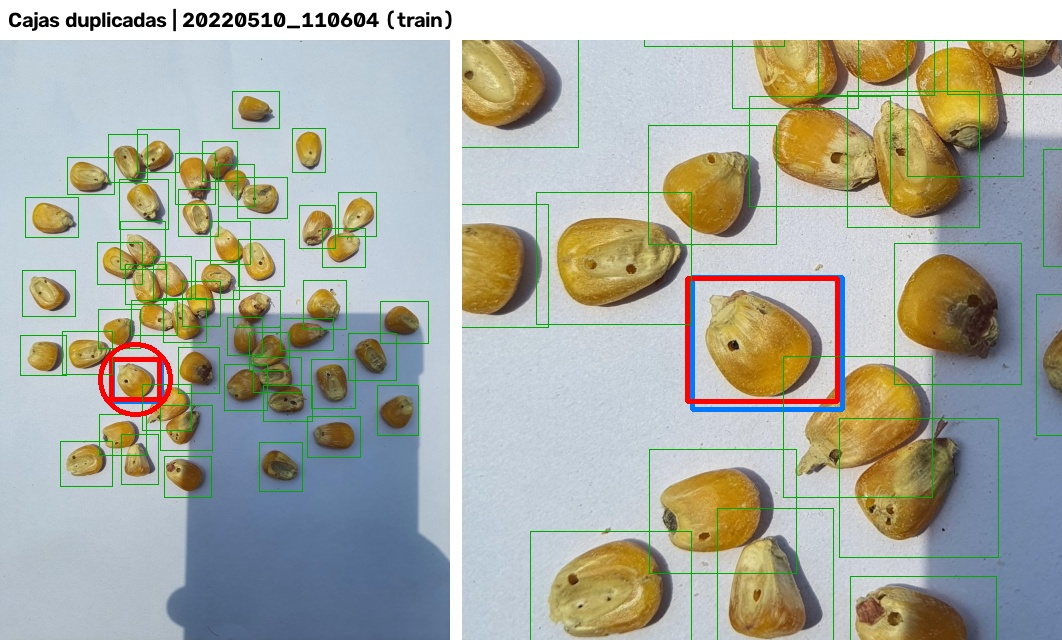

Clase rara en sesión casi monoclase - Healthy (2 de 311 cajas) en una sesión de Fungus


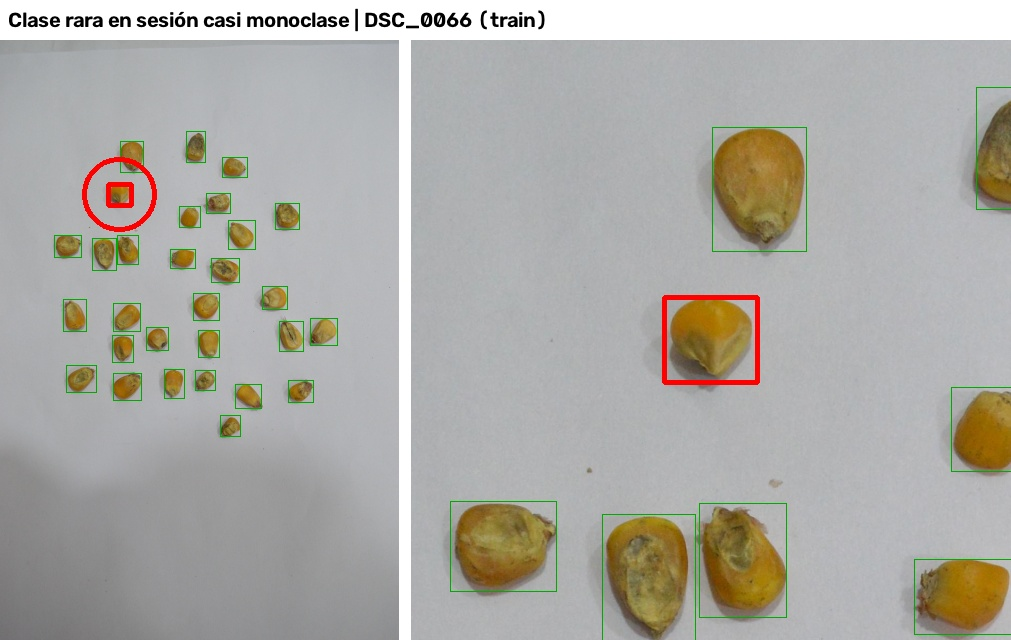

Posible etiquetado incompleto - 2 cajas; mediana de su sesión 30


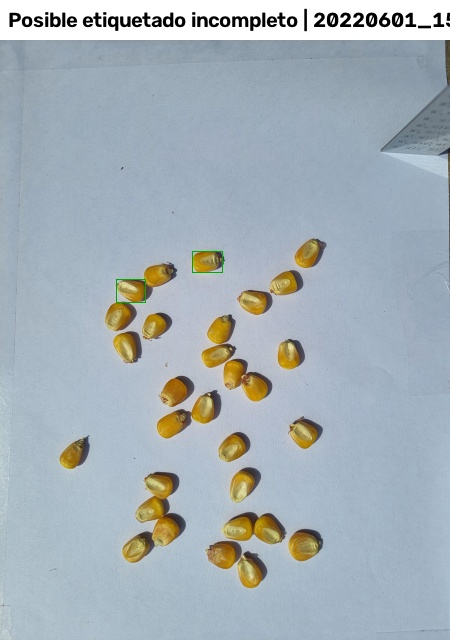

Tamaño atípico - muy pequeña para Organic foreign material (z = -4.3)


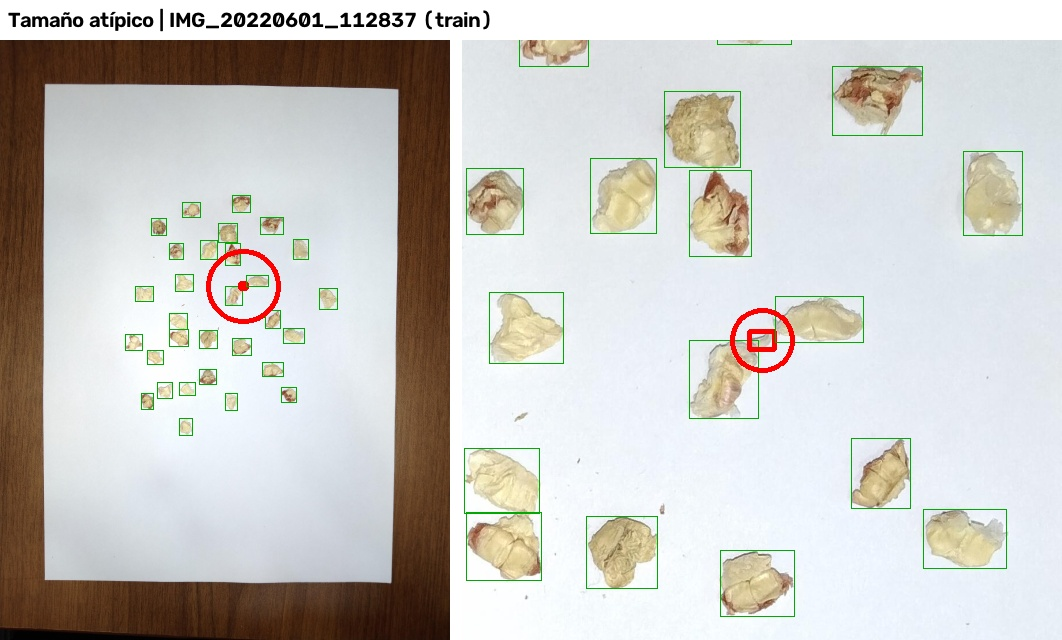

In [18]:
por_stem = {r['stem']: r for r in inv}
NOMBRE_ARCHIVO = {'Caja degenerada': 'caja_degenerada', 'Cajas duplicadas': 'cajas_duplicadas', 'Tamaño atípico': 'tamano_atipico',
                  'Clase rara en sesión casi monoclase': 'clase_rara', 'Posible etiquetado incompleto': 'etiquetado_incompleto',
                  'Relación de aspecto atípica': 'relacion_aspecto', 'Caja fuera de la imagen': 'fuera_imagen'}
for tipo, g in problemas.groupby('tipo'):
    p = g.iloc[0]
    pareja = None if pd.isna(p.pareja) else int(p.pareja)
    ruta = SALIDA / 'calidad' / f'ejemplo_{NOMBRE_ARCHIVO[tipo]}.jpg'
    ruta.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(ruta), C.imagen_evidencia(por_stem[p.stem], int(p.caja), pareja, f"{tipo} | {C.nombre_roboflow(p.stem)} ({p.split})"))
    print(tipo, '-', p.detalle)
    display(Mostrar(filename=str(ruta), width=900))

**Límite de la detección automática.** Los controles encuentran cajas mal trazadas, duplicadas o de tamaño anómalo, y las omisiones groseras (una imagen con 2 cajas en una sesión de 30 granos). No detectan omisiones parciales ni errores de clase en granos individuales, que exigen revisión visual.

## 10. Propuesta de consolidación de clases

1. **Excluir `Other Edible Seeds`:** imágenes con solo semillas de otra especie, sin granos de maíz.
2. **Excluir las impurezas** (`Inorganic` y `Organic foreign material`): objetos de forma muy heterogénea, a menudo apilados, que no son granos.
3. **Unir `Immature` con `Healthy`:** el Codex CXS 153-1985 no cuenta la inmadurez entre los granos defectuosos.
4. **Agrupar en `Defect`** `Broken`, `Damage`, `Fungus`, `Shriveled` y `Weeveled`.

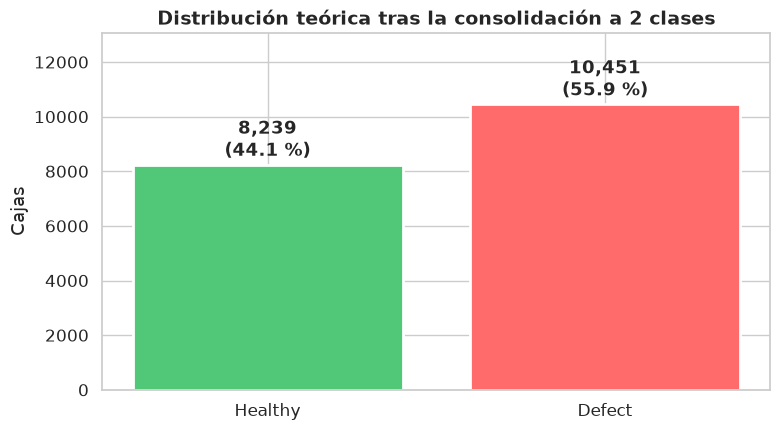

Se excluyen 6686 cajas (26.3 %)


In [19]:
df['clase_final'] = df.id_clase.map(lambda c: C.CLASES_BINARIAS[C.MAPEO_BINARIO[c]] if c in C.CLASES_MAIZ else None)
final = df.clase_final.value_counts().reindex(C.CLASES_BINARIAS)
fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(final.index, final.values, color=[C.COLOR_BINARIO[c] for c in final.index], edgecolor='white', linewidth=2)
for b, v in zip(barras, final.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 100, f'{v:,}\n({100 * v / final.sum():.1f} %)', ha='center', va='bottom', fontweight='bold')
ax.set_ylim(0, final.max() * 1.25); ax.set_ylabel('Cajas'); ax.set_title('Distribución teórica tras la consolidación a 2 clases')
C.guardar(SALIDA, 'eda_distribucion_teorica_2clases.png')
print(f"Se excluyen {df.clase_final.isna().sum()} cajas ({100 * df.clase_final.isna().mean():.1f} %)")

## 11. Conclusiones

1. **Clases:** fuerte desbalance (`Broken` y `Damage` en torno al 4 % cada una). Tras consolidar a `Healthy`/`Defect`, las dos clases quedan cerca del equilibrio.
2. **Imágenes:** 9 resoluciones de alrededor de 13.8 MP; hay que llevarlas a una resolución común. Por el tamaño de los granos, 640 px puede ser insuficiente: se comparan 640, 960 y 1280 px en la Actividad 1.2.
3. **Escenas monoclase:** cada bandeja se fotografió con un solo tipo de grano (97.5 % de imágenes con una sola clase).
4. **Partición original con fuga:** fotos de una misma sesión están en splits distintos; hay que re-particionar con la sesión o el lote de captura como unidad.
5. **Etiquetado:** hay cajas degeneradas, duplicadas, de tamaño anómalo y alguna imagen casi sin etiquetar; se corrigen en Roboflow (`1.2_limpieza_etiquetas`).